In [56]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


## 1. Introduction

This lab focuses on analyzing the Telco Customer Churn dataset using Python and Pandas. The work involves loading the dataset, displaying its head and tail, performing data preprocessing, and exploring customer churn based on demographic characteristics, services, and payment methods. The aim is to understand customer churn patterns by examining the relationship between these attributes and customer churn.

In [57]:
import pandas as pd

print("Pandas imported successfully!")

Pandas imported successfully!


In [58]:
import pandas as pd
import os

# Find the CSV file attached to this notebook
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [59]:
print("Kaggle is working!")

Kaggle is working!


In [60]:
import os

print(os.listdir('/kaggle/input'))

['datasets']


In [61]:
import os

print(os.listdir('/kaggle/input/datasets'))

['blastchar']


In [62]:
import os

print(os.listdir('/kaggle/input/datasets/blastchar'))

['telco-customer-churn']


In [63]:
import os

print(os.listdir(
    '/kaggle/input/datasets/blastchar/telco-customer-churn'
))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [64]:
import pandas as pd

# Load the dataset
df = pd.read_csv(
    '/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv'
)

# Display a success message
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [65]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [66]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [67]:

# Display the data type of each attribute
df.dtypes


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [68]:

# Count missing values in each attribute
df.isnull().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [69]:
# Convert TotalCharges to numeric values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Count missing values again
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [70]:
# Display attributes that contain missing values
df.isnull().sum()[df.isnull().sum() > 0]

TotalCharges    11
dtype: int64

In [71]:
# Remove rows containing missing values
df = df.dropna()

# Check the remaining missing values
df.isnull().sum().sum()

np.int64(0)

In [72]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [73]:
# Convert Churn values from Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Display the first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Visualizations

The bar charts below make the analysis easier to interpret. The first chart shows the number of customers who stayed or churned. The remaining charts compare **churn rates (%)** across customer groups. A churn rate is the percentage of customers in a group who left, not the total number of customers in that group.

In [74]:
print(df['Churn'].value_counts())
print("\nChurn data type:", df['Churn'].dtype)

Churn
0    5163
1    1869
Name: count, dtype: int64

Churn data type: int64


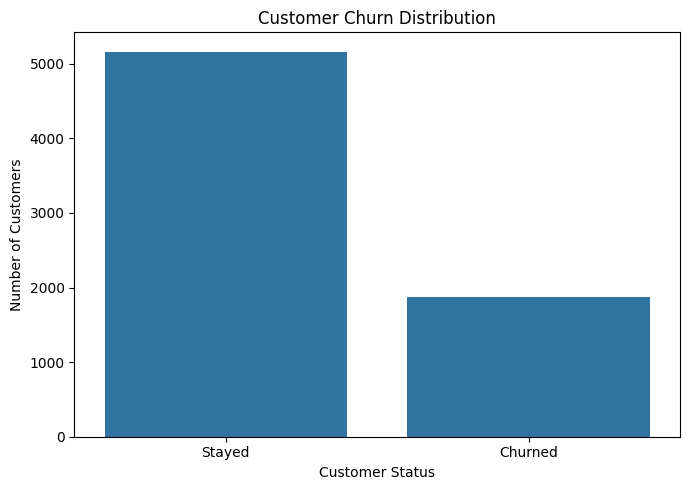

In [75]:
# Visualize the overall distribution of customers who churned and stayed
import matplotlib.pyplot as plt
import seaborn as sns

churn_labels = df['Churn'].map({0: 'Stayed', 1: 'Churned'}).value_counts()
plt.figure(figsize=(7, 5))
sns.barplot(x=churn_labels.index, y=churn_labels.values)
plt.title('Customer Churn Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

In [76]:
# Analyze churn by gender
df.groupby('gender')['Churn'].mean() * 100

gender
Female    26.959518
Male      26.204565
Name: Churn, dtype: float64

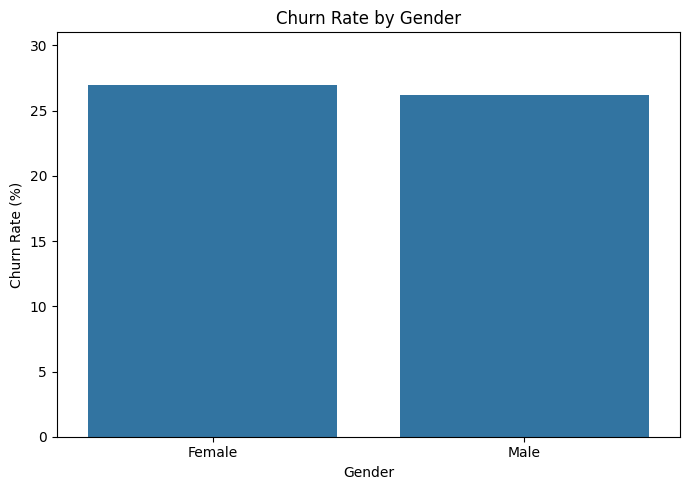

In [77]:
# Visualize churn rate by gender
gender_churn = (df.groupby('gender')['Churn'].mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
sns.barplot(x=gender_churn.index, y=gender_churn.values)
plt.title('Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(gender_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Female customers have a churn rate of approximately 26.96%, while male customers have a rate of 26.20%. The difference is small, indicating that churn rates are similar across the two gender groups.

In [78]:
# Analyze customer churn by senior citizen status
df.groupby('SeniorCitizen')['Churn'].mean() * 100

SeniorCitizen
0    23.650255
1    41.681261
Name: Churn, dtype: float64

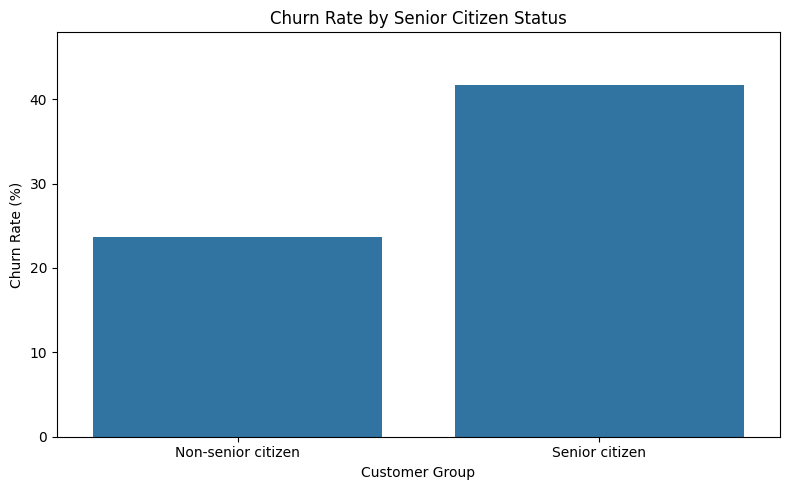

In [79]:
# Visualize churn rate by senior citizen status
senior_churn = (df.groupby('SeniorCitizen')['Churn'].mean() * 100)
senior_churn.index = senior_churn.index.map({0: 'Non-senior citizen', 1: 'Senior citizen'})
plt.figure(figsize=(8, 5))
sns.barplot(x=senior_churn.index, y=senior_churn.values)
plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Customer Group')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(senior_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Senior citizens have a churn rate of approximately 41.68%, compared with 23.65% for non-senior citizens. This shows a substantially higher churn rate among senior citizens.

In [80]:
# Analyze customer churn by partner status
df.groupby('Partner')['Churn'].mean() * 100

Partner
No     32.976092
Yes    19.717065
Name: Churn, dtype: float64

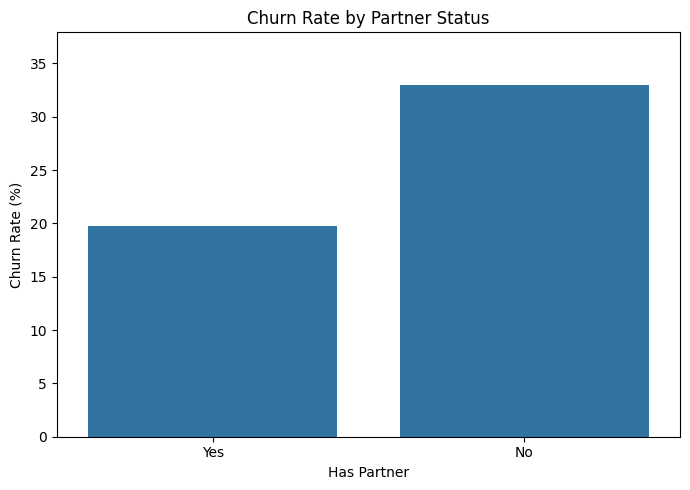

In [81]:
# Visualize churn rate by partner status
partner_churn = df.groupby('Partner')['Churn'].mean().mul(100).reindex(['Yes', 'No'])
plt.figure(figsize=(7, 5))
sns.barplot(x=partner_churn.index, y=partner_churn.values)
plt.title('Churn Rate by Partner Status')
plt.xlabel('Has Partner')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(partner_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Customers without partners have a churn rate of approximately 32.98%, compared with 19.72% for customers with partners. Customers without partners are more likely to churn in this dataset.

In [82]:
# Analyze customer churn by dependent status
df.groupby('Dependents')['Churn'].mean() * 100

Dependents
No     31.279140
Yes    15.531205
Name: Churn, dtype: float64

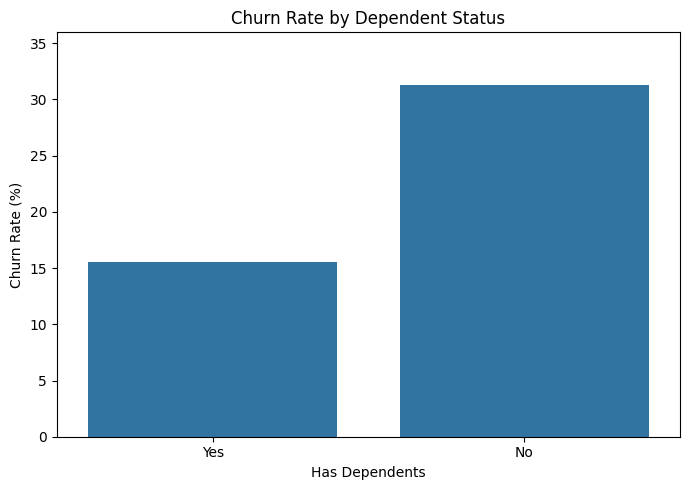

In [83]:
# Visualize churn rate by dependent status
dependent_churn = df.groupby('Dependents')['Churn'].mean().mul(100).reindex(['Yes', 'No'])
plt.figure(figsize=(7, 5))
sns.barplot(x=dependent_churn.index, y=dependent_churn.values)
plt.title('Churn Rate by Dependent Status')
plt.xlabel('Has Dependents')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(dependent_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Customers without dependents have a churn rate of approximately 31.28%, compared with 15.53% for customers with dependents. The results show a higher churn rate among customers without dependents.

In [84]:
# Analyze customer churn by phone service
df.groupby('PhoneService')['Churn'].mean() * 100

PhoneService
No     25.000000
Yes    26.747481
Name: Churn, dtype: float64

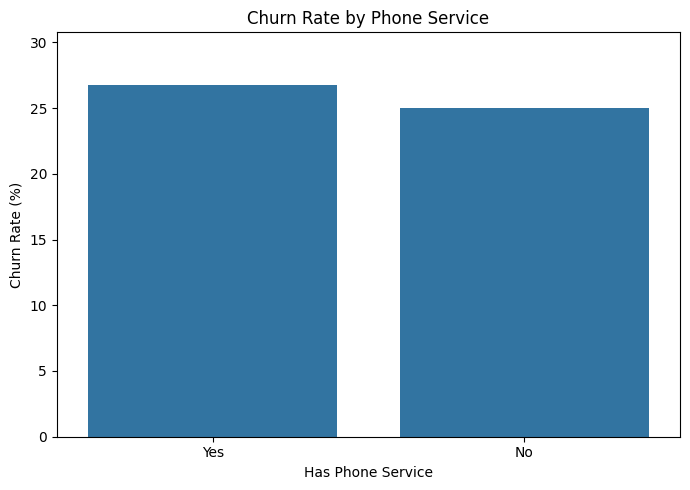

In [85]:
# Visualize churn rate by phone service
phone_churn = df.groupby('PhoneService')['Churn'].mean().mul(100).reindex(['Yes', 'No'])
plt.figure(figsize=(7, 5))
sns.barplot(x=phone_churn.index, y=phone_churn.values)
plt.title('Churn Rate by Phone Service')
plt.xlabel('Has Phone Service')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(phone_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation 
Customers with phone service have a churn rate of approximately 26.75%, while customers without phone service have a rate of 25%. The difference is relatively small.

In [86]:
# Analyze customer churn by contract type
df.groupby('Contract')['Churn'].mean() * 100

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64

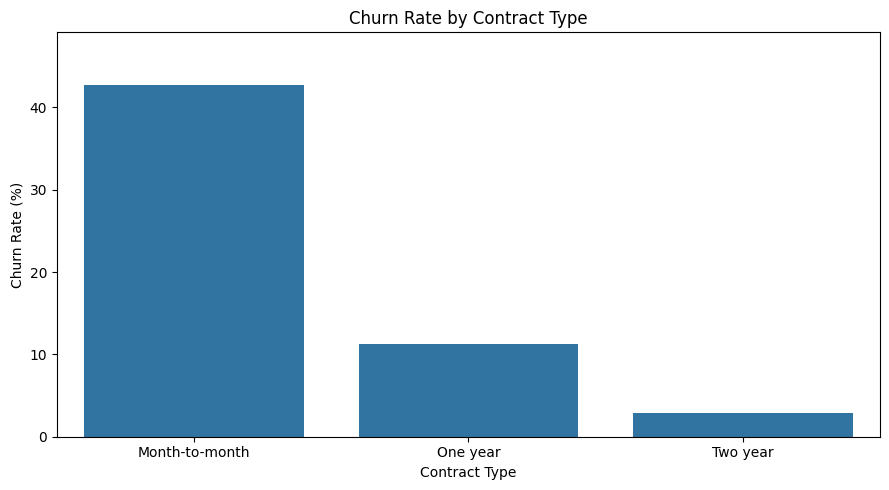

In [87]:
# Visualize churn rate by contract type
contract_order = ['Month-to-month', 'One year', 'Two year']
contract_churn = df.groupby('Contract')['Churn'].mean().mul(100).reindex(contract_order)
plt.figure(figsize=(9, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values)
plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(contract_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Month-to-month customers have the highest churn rate at approximately 42.71%. Customers with one-year contracts have a rate of 11.28%, while those with two-year contracts have the lowest rate at 2.85%. Longer contracts are associated with lower churn rates.

In [88]:
# Analyze customer churn by paperless billing
df.groupby('PaperlessBilling')['Churn'].mean() * 100

PaperlessBilling
No     16.375698
Yes    33.589251
Name: Churn, dtype: float64

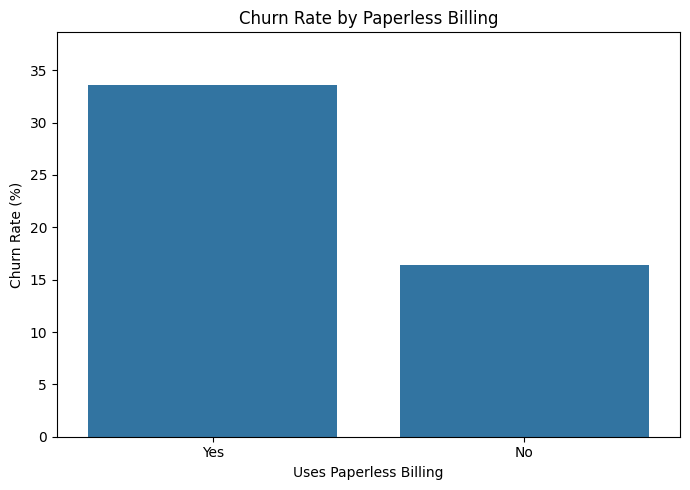

In [89]:
# Visualize churn rate by paperless billing
paperless_churn = df.groupby('PaperlessBilling')['Churn'].mean().mul(100).reindex(['Yes', 'No'])
plt.figure(figsize=(7, 5))
sns.barplot(x=paperless_churn.index, y=paperless_churn.values)
plt.title('Churn Rate by Paperless Billing')
plt.xlabel('Uses Paperless Billing')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, max(paperless_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interpretation
Customers using paperless billing have a churn rate of approximately 33.59%, compared with 16.38% for customers who do not use paperless billing. This shows a higher churn rate among paperless billing users.

In [90]:
# Analyze customer churn by payment method
df.groupby('PaymentMethod')['Churn'].mean() * 100

PaymentMethod
Bank transfer (automatic)    16.731518
Credit card (automatic)      15.253123
Electronic check             45.285412
Mailed check                 19.201995
Name: Churn, dtype: float64

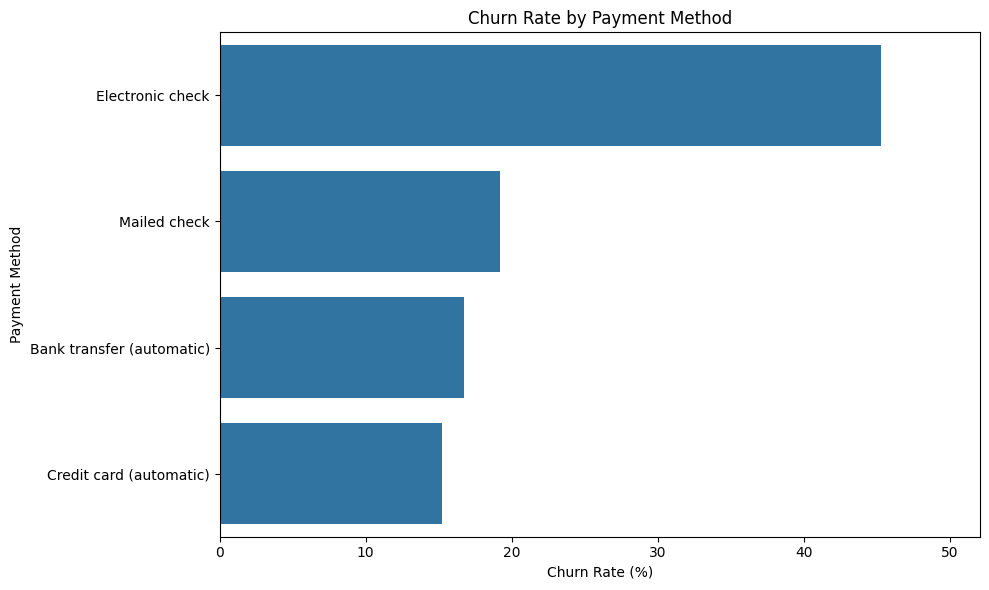

In [91]:
# Visualize churn rate by payment method
payment_churn = df.groupby('PaymentMethod')['Churn'].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=payment_churn.values, y=payment_churn.index)
plt.title('Churn Rate by Payment Method')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Payment Method')
plt.xlim(0, max(payment_churn.values) * 1.15)
plt.tight_layout()
plt.show()

## Interepretation
Electronic check users have the highest churn rate at approximately 45.29%. Credit card users with automatic payments have the lowest rate at approximately 15.25%. Bank transfer users have a rate of 16.73%, and mailed check users have a rate of 19.20%.

## Conclusion

The analysis shows that customer churn rates differ across several customer characteristics and services. Month-to-month contract customers and electronic check users have the highest churn rates among the groups analyzed. Senior citizens and customers without partners or dependents also have higher churn rates. Gender and phone service show relatively small differences in churn rates. These results identify patterns associated with customer churn in the dataset.